# Activity 2: Binary Classification with Logistic Regression, Breast Tumour Screening
**Course:** Regression and Classification Algorithms | **Class:** T.Y. B.Tech AI & DS, Sem V | **Unit II**
**Name / Roll No:** Pratham Mahajan, Roll No. AD3230 | **GitHub:** [complexiota](https://github.com/complexiota)

## 1. Problem framing (Stage 1)
**Role:** I am a data scientist at a health-screening programme.
**User and decision:** A screening team looks at measurements from a fine-needle biopsy image and must decide whether a case should be **flagged for urgent specialist review**. The model's yes/no output prioritises cases; it never makes the diagnosis itself.
**Target (y):** `malignant` (1 = malignant tumour = **positive class**, 0 = benign = negative class).
**Cost of errors:** A **false negative** (missed cancer) delays treatment and can cost a life. A **false positive** (false alarm) causes anxiety and an extra test. False negatives are worse here, so **recall** is the priority metric and I will consider a threshold below 0.5.
**Success metric:** recall (sensitivity) first, then precision, F1 and ROC-AUC; the model must beat the majority-class baseline.

## 2. Data source and class definitions (Stage 2)
**Dataset:** Breast Cancer Wisconsin (Diagnostic), built into scikit-learn (`sklearn.datasets.load_breast_cancer`).
**Source:** Wolberg, W. H., Street, W. N. and Mangasarian, O. L., UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
**One row** = one biopsy sample described by measurements of cell nuclei (no names or personal identifiers, so the data is non-personal).

**Classes:** `1 = malignant` (positive class, cancerous) and `0 = benign` (negative class, non-cancerous). Note: scikit-learn codes these the other way round (0 = malignant), so I flip the labels so that the positive class is the one the team cares about.

**Features used (6 of the "mean" measurements):** mean radius, mean texture, mean smoothness, mean compactness, mean concave points, mean symmetry.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn, platform
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

SEED = 42
np.random.seed(SEED)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1


## 3. Load and inspect the data (Stage 2)

In [2]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
df["malignant"] = 1 - df["target"]          # flip: 1 = malignant (positive), 0 = benign
df = df.drop(columns="target")
FEATURES = ["mean radius", "mean texture", "mean smoothness", "mean compactness", "mean concave points", "mean symmetry"]
TARGET = "malignant"
df = df[FEATURES + [TARGET]]
print("Rows, columns:", df.shape, "| features:", len(FEATURES), "| target column:", TARGET)
df.head()

Rows, columns: (569, 7) | features: 6 | target column: malignant


,mean radius,mean texture,mean smoothness,mean compactness,mean concave points,mean symmetry,malignant
0,17.99,10.38,0.11840,0.27760,0.14710,0.2419,1
1,20.57,17.77,0.08474,0.07864,0.07017,0.1812,1
2,19.69,21.25,0.10960,0.15990,0.12790,0.2069,1
3,11.42,20.38,0.14250,0.28390,0.10520,0.2597,1
4,20.29,14.34,0.10030,0.13280,0.10430,0.1809,1


In [3]:
print(df.dtypes, "\n")
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Unique label values:", sorted(df[TARGET].unique()))
df.describe().T

mean radius            float64
mean texture           float64
mean smoothness        float64
mean compactness       float64
mean concave points    float64
mean symmetry          float64
malignant                int64
dtype: object 

Missing values:
 mean radius            0
mean texture           0
mean smoothness        0
mean compactness       0
mean concave points    0
mean symmetry          0
malignant              0
dtype: int64 

Duplicate rows: 0
Unique label values: [np.int64(0), np.int64(1)]


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.0740,0.2012
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.1957,0.3040
malignant,569.0,0.372583,0.483918,0.00000,0.00000,0.00000,1.0000,1.0000


**Observation:** The data has no missing values and the labels are consistent (only 0 and 1). All features are numeric, so no encoding is needed. The feature scales differ a lot (radius is about 6 to 28, smoothness about 0.05 to 0.16), which matters for the optimiser (see scaling below).

malignant
0    357
1    212
Name: count, dtype: int64 
 malignant
0    62.7 %
1    37.3 %
Name: count, dtype: object


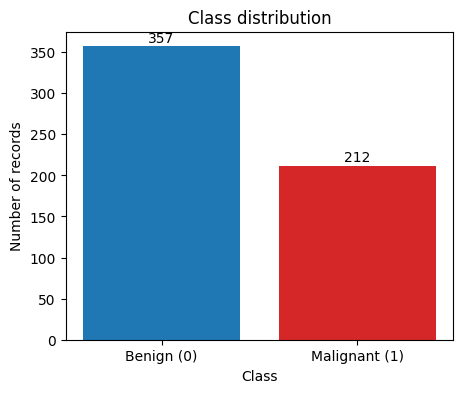

In [4]:
counts = df[TARGET].value_counts().sort_index()
print(counts, "\n", (counts / len(df) * 100).round(1).astype(str) + " %")
plt.figure(figsize=(5, 4))
plt.bar(["Benign (0)", "Malignant (1)"], counts.values, color=["tab:blue", "tab:red"])
plt.title("Class distribution"); plt.xlabel("Class"); plt.ylabel("Number of records")
for i, v in enumerate(counts.values): plt.text(i, v + 5, str(v), ha="center")
plt.show()

**Observation:** The classes are moderately imbalanced (about 63% benign and 37% malignant). A model that always predicts "benign" would already get about 63% accuracy, so accuracy alone cannot be trusted. I will compare against that baseline and focus on recall.

## 4. Prepare the features (Stage 5)
- **Missing values:** none, so no imputation was needed.
- **Encoding:** not needed, because all features are numeric.
- **Identifier columns:** none exist in the selected columns, so nothing leaks.
- **Scaling:** I standardise the features (mean 0, standard deviation 1). Logistic regression is fitted by an iterative optimiser, and features on very different scales slow or destabilise convergence and make coefficients hard to compare. The scaler is fitted on **training data only**, to avoid leaking test information.

In [5]:
X = df[FEATURES]; y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train size:", len(X_train), "| Test size:", len(X_test))
print("Train class counts:\n", y_train.value_counts().sort_index().to_string())
print("Test class counts:\n", y_test.value_counts().sort_index().to_string())
print("Malignant share  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

scaler = StandardScaler().fit(X_train)               # fit on train ONLY
X_train_s = scaler.transform(X_train); X_test_s = scaler.transform(X_test)

Train size: 455 | Test size: 114
Train class counts:
 malignant
0    285
1    170
Test class counts:
 malignant
0    72
1    42
Malignant share  train: 0.374 | test: 0.368


**Why stratified:** `stratify=y` keeps the same benign/malignant proportion in both sets, so the test set is a fair mini-copy of the whole data.

## 5. Understanding Logistic Regression
**Why linear regression is unsuitable for a class label:** Linear regression outputs any real number (like -3 or 7), which is not a probability, and a straight line is pulled around by extreme points. A class label is a category (0 or 1), so we need an output that is bounded between 0 and 1 and shaped like a smooth switch.

**Sigmoid and threshold:** Logistic regression computes a score z = b0 + b1x1 + ... and passes it through the sigmoid, **p = 1 / (1 + e^(-z))**. This squeezes any z into a probability between 0 and 1. The **decision threshold** turns the probability into a label: predict malignant if p >= threshold (0.5 by default). Moving the threshold trades false alarms against missed cases.

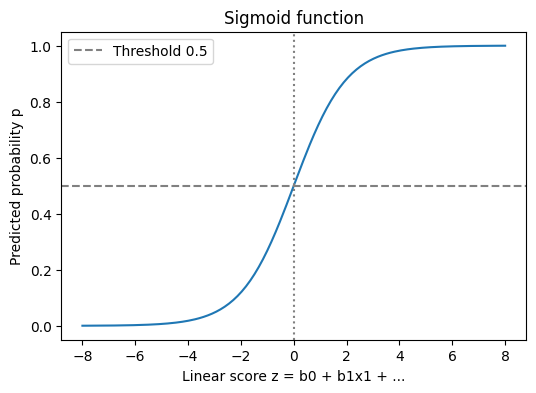

In [6]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 4))
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, color="grey", ls="--", label="Threshold 0.5"); plt.axvline(0, color="grey", ls=":")
plt.title("Sigmoid function"); plt.xlabel("Linear score z = b0 + b1x1 + ..."); plt.ylabel("Predicted probability p")
plt.legend(); plt.show()

## 6. Train the model (Stage 5)

In [7]:
model = LogisticRegression(random_state=SEED, max_iter=1000)   # default L2 regularisation, C=1.0
model.fit(X_train_s, y_train)
print("Settings:", model.get_params())
print("\nIntercept:", round(model.intercept_[0], 4))
coef = pd.DataFrame({"Feature": FEATURES, "Coefficient (per 1 SD)": model.coef_[0],
                     "Odds multiplier exp(coef)": np.exp(model.coef_[0])}).round(4)
coef.sort_values("Coefficient (per 1 SD)", ascending=False)

Settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Intercept: -0.6384


,Feature,Coefficient (per 1 SD),Odds multiplier exp(coef)
0,mean radius,2.6169,13.6934
4,mean concave points,2.4802,11.9434
1,mean texture,1.4182,4.1298
2,mean smoothness,0.7422,2.1006
5,mean symmetry,0.4121,1.5099
3,mean compactness,-0.2487,0.7798


**How to read the coefficients:** features were standardised, so each coefficient is the change in the **log-odds** of malignancy for a 1-standard-deviation increase in that feature, holding the others constant. A **positive** coefficient raises the probability of the malignant class; a **negative** one lowers it. `exp(coef)` is the odds multiplier (for example 2.0 means the odds double). The largest absolute coefficients matter most. Associations are not causes, and correlated features (such as radius and concave points) share the credit.

## 7. Probabilities, labels and the effect of the threshold

In [8]:
proba = model.predict_proba(X_test_s)[:, 1]          # probability of malignant
pred05 = (proba >= 0.5).astype(int)
sample = pd.DataFrame({"Actual": y_test.values, "P(malignant)": proba.round(3), "Predicted (0.5)": pred05}).head(10)
sample

,Actual,P(malignant),Predicted (0.5)
0,0,0.001,0
1,1,1.000,1
2,0,0.563,1
3,1,0.593,1
4,0,0.690,1
5,0,0.018,0
6,1,0.428,0
7,0,0.015,0
8,0,0.002,0
9,0,0.065,0


In [9]:
for t in [0.3, 0.5, 0.7]:
    print(f"Threshold {t}: {int((proba >= t).sum())} of {len(proba)} test records predicted malignant "
          f"(actual malignant = {int(y_test.sum())})")

Threshold 0.3: 48 of 114 test records predicted malignant (actual malignant = 42)
Threshold 0.5: 44 of 114 test records predicted malignant (actual malignant = 42)
Threshold 0.7: 36 of 114 test records predicted malignant (actual malignant = 42)


**Observation:** a lower threshold flags more records as malignant (more caution, more false alarms); a higher threshold flags fewer (fewer false alarms, more missed cases).

## 8. Evaluation on the test set (Stage 6)

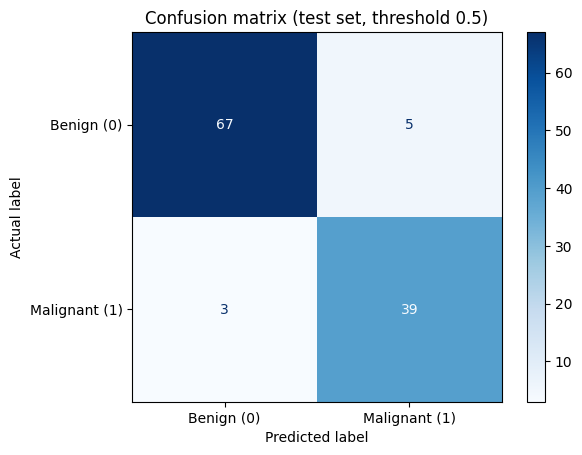

TP = 39  (malignant correctly flagged)
FP = 5  (benign wrongly flagged: false alarm, extra test)
FN = 3  (malignant missed: the dangerous error)
TN = 67  (benign correctly cleared)


In [10]:
cm = confusion_matrix(y_test, pred05)
tn, fp, fn, tp = cm.ravel()
ConfusionMatrixDisplay(cm, display_labels=["Benign (0)", "Malignant (1)"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set, threshold 0.5)"); plt.xlabel("Predicted label"); plt.ylabel("Actual label"); plt.show()
print(f"TP = {tp}  (malignant correctly flagged)")
print(f"FP = {fp}  (benign wrongly flagged: false alarm, extra test)")
print(f"FN = {fn}  (malignant missed: the dangerous error)")
print(f"TN = {tn}  (benign correctly cleared)")

In [11]:
acc  = (tp + tn) / (tp + tn + fp + fn)
prec = tp / (tp + fp)
rec  = tp / (tp + fn)
spec = tn / (tn + fp)
f1   = 2 * prec * rec / (prec + rec)
auc  = roc_auc_score(y_test, proba)
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall (sensitivity)", "Specificity", "F1-score", "ROC-AUC"],
    "Formula": ["(TP+TN)/(TP+TN+FP+FN)", "TP/(TP+FP)", "TP/(TP+FN)", "TN/(TN+FP)", "2*P*R/(P+R)", "Area under ROC curve"],
    "Test-set result": [acc, prec, rec, spec, f1, auc]}).round(4)
results

,Metric,Formula,Test-set result
0,Accuracy,(TP+TN)/(TP+TN+FP+FN),0.9298
1,Precision,TP/(TP+FP),0.8864
2,Recall (sensitivity),TP/(TP+FN),0.9286
3,Specificity,TN/(TN+FP),0.9306
4,F1-score,2*P*R/(P+R),0.9070
5,ROC-AUC,Area under ROC curve,0.9825


**Interpretation (check against the numbers above):** Accuracy is the share of all correct predictions. **Precision** says how many flagged cases are truly malignant. **Recall** says how many real malignant cases the model caught; this is the number the team cares most about. **Specificity** says how many benign cases were correctly cleared. **F1** balances precision and recall. A recall below about 0.90 would be worrying for a screening tool.

In [12]:
print(classification_report(y_test, pred05, target_names=["Benign (0)", "Malignant (1)"], digits=3))

               precision    recall  f1-score   support

   Benign (0)      0.957     0.931     0.944        72
Malignant (1)      0.886     0.929     0.907        42

     accuracy                          0.930       114
    macro avg      0.922     0.930     0.925       114
 weighted avg      0.931     0.930     0.930       114



In [13]:
# Majority-class baseline
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
dp = dummy.predict(X_test_s)
base = pd.DataFrame({
    "Model": ["Majority-class baseline", "Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, dp), acc],
    "Recall (malignant)": [recall_score(y_test, dp), rec],
    "F1": [f1_score(y_test, dp, zero_division=0), f1]}).round(4)
base

,Model,Accuracy,Recall (malignant),F1
0,Majority-class baseline,0.6316,0.0000,0.000
1,Logistic Regression,0.9298,0.9286,0.907


**Why accuracy alone can mislead:** the baseline never predicts malignant, so its recall is 0 (it would miss every cancer), yet its accuracy looks acceptable (about 63%) simply because most cases are benign. With imbalanced classes you must also look at recall, precision and F1.

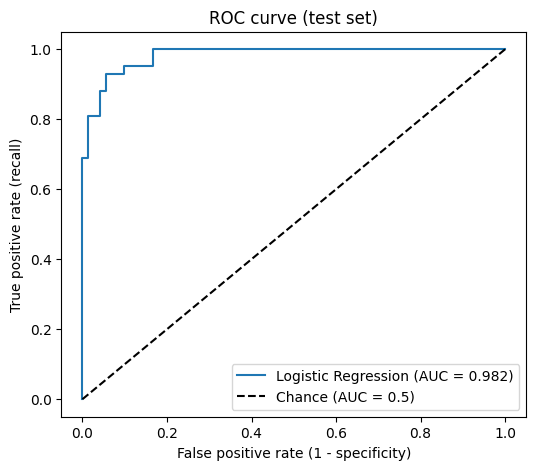

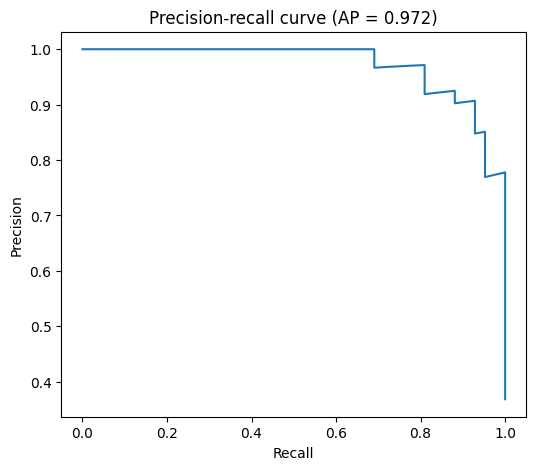

In [14]:
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.5)")
plt.title("ROC curve (test set)"); plt.xlabel("False positive rate (1 - specificity)"); plt.ylabel("True positive rate (recall)")
plt.legend(); plt.show()

p_, r_, _ = precision_recall_curve(y_test, proba)
plt.figure(figsize=(6, 5)); plt.plot(r_, p_)
plt.title(f"Precision-recall curve (AP = {average_precision_score(y_test, proba):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.show()

**ROC-AUC meaning:** it is the probability that a randomly chosen malignant record gets a higher predicted probability than a randomly chosen benign record. 0.5 is chance and 1.0 is perfect ranking; a value close to 1 means the model ranks positives above negatives very well across all thresholds.

### Threshold comparison

In [15]:
rows = []
for t in [0.3, 0.5, 0.7]:
    p_t = (proba >= t).astype(int)
    rows.append({"Threshold": t, "Predicted positive": int(p_t.sum()),
                 "Accuracy": accuracy_score(y_test, p_t), "Precision": precision_score(y_test, p_t, zero_division=0),
                 "Recall": recall_score(y_test, p_t), "F1-score": f1_score(y_test, p_t),
                 "FN (missed)": int(((p_t == 0) & (y_test.values == 1)).sum()),
                 "FP (false alarms)": int(((p_t == 1) & (y_test.values == 0)).sum())})
thr = pd.DataFrame(rows).round(4)
thr

,Threshold,Predicted positive,Accuracy,Precision,Recall,F1-score,FN (missed),FP (false alarms)
0,0.3,48,0.9123,0.8333,0.9524,0.8889,2,8
1,0.5,44,0.9298,0.8864,0.9286,0.9070,3,5
2,0.7,36,0.9123,0.9444,0.8095,0.8718,8,2


**Trade-off:** as the threshold goes **down**, recall rises (fewer missed cancers) but precision falls (more false alarms). As it goes **up**, precision rises but recall falls (more cancers missed).

**Which error is costlier here?** A false negative (a missed malignant tumour). A false positive only leads to an extra confirmatory test. So I recommend the threshold from the table that keeps recall high (ideally >= 0.95) while keeping precision acceptable; see the automatic pick below.

In [16]:
ok = thr[thr["Recall"] >= 0.95]
rec_t = ok.sort_values(["Precision", "Threshold"], ascending=False).iloc[0] if len(ok) else thr.sort_values("Recall", ascending=False).iloc[0]
print(f"Recommended threshold: {rec_t['Threshold']}  (recall {rec_t['Recall']:.3f}, precision {rec_t['Precision']:.3f}, "
      f"{int(rec_t['FN (missed)'])} missed cancers, {int(rec_t['FP (false alarms)'])} false alarms on the test set)")

Recommended threshold: 0.3  (recall 0.952, precision 0.833, 2 missed cancers, 8 false alarms on the test set)


In [17]:
# Training vs test comparison (overfitting / underfitting check)
ptr = model.predict(X_train_s); pte = pred05
cmpr = pd.DataFrame({
    "Set": ["Train", "Test"],
    "Accuracy": [accuracy_score(y_train, ptr), accuracy_score(y_test, pte)],
    "Precision": [precision_score(y_train, ptr), precision_score(y_test, pte)],
    "Recall": [recall_score(y_train, ptr), recall_score(y_test, pte)],
    "F1": [f1_score(y_train, ptr), f1_score(y_test, pte)],
    "ROC-AUC": [roc_auc_score(y_train, model.predict_proba(X_train_s)[:, 1]), auc]}).round(4)
cmpr

,Set,Accuracy,Precision,Recall,F1,ROC-AUC
0,Train,0.9495,0.9623,0.9000,0.9301,0.9872
1,Test,0.9298,0.8864,0.9286,0.9070,0.9825


**Comment:** if train and test scores are close, the model is neither badly overfitting nor underfitting. A large gap (train much higher) means overfitting; both low means underfitting. Because a very high score can also come from leakage, I checked that the scaler was fitted on training data only, no identifier column is used, and the target was not included in the features.

## 9. Visualise the decision behaviour

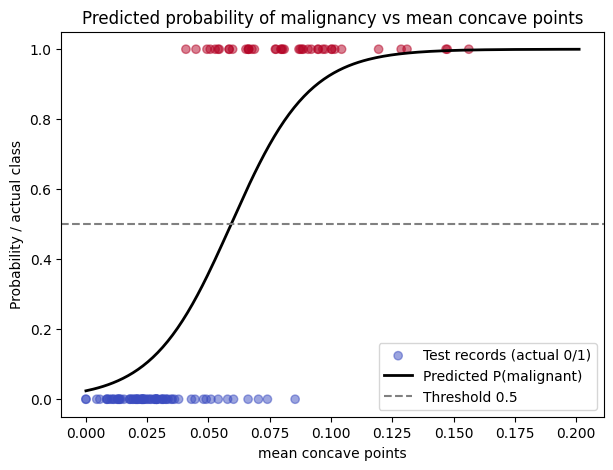

In [18]:
feat = "mean concave points"
j = FEATURES.index(feat)
grid_raw = np.linspace(X[feat].min(), X[feat].max(), 200)
grid = np.tile(X_train.mean().values, (200, 1)); grid[:, j] = grid_raw       # other features held at their mean
pg = model.predict_proba(scaler.transform(pd.DataFrame(grid, columns=FEATURES)))[:, 1]
plt.figure(figsize=(7, 5))
plt.scatter(X_test[feat], y_test, c=y_test, cmap="coolwarm", alpha=0.5, label="Test records (actual 0/1)")
plt.plot(grid_raw, pg, "k", lw=2, label="Predicted P(malignant)")
plt.axhline(0.5, color="grey", ls="--", label="Threshold 0.5")
plt.title("Predicted probability of malignancy vs mean concave points"); plt.xlabel(feat); plt.ylabel("Probability / actual class"); plt.legend(); plt.show()

**Observation:** the probability follows an S-shaped curve. At low concave-points values the model is confident the tumour is benign, at high values it is confident it is malignant, and it passes through 0.5 in an uncertain middle zone where mistakes are most likely.

## 10. Classify a new example and conclude

In [19]:
print(X.describe().loc[["min", "max"]].T)    # check the new record is inside this range
new = pd.DataFrame([{"mean radius": 14.0, "mean texture": 19.0, "mean smoothness": 0.096,
                     "mean compactness": 0.10, "mean concave points": 0.05, "mean symmetry": 0.18}])
p_new = model.predict_proba(scaler.transform(new))[0, 1]
t = float(rec_t["Threshold"])
print(f"Predicted probability of malignant: {p_new:.3f}")
print(f"Class at threshold 0.5: {'Malignant' if p_new >= 0.5 else 'Benign'} | at recommended threshold {t}: {'Malignant' if p_new >= t else 'Benign'}")

                         min      max
mean radius          6.98100  28.1100
mean texture         9.71000  39.2800
mean smoothness      0.05263   0.1634
mean compactness     0.01938   0.3454
mean concave points  0.00000   0.2012
mean symmetry        0.10600   0.3040
Predicted probability of malignant: 0.301
Class at threshold 0.5: Benign | at recommended threshold 0.3: Malignant


### Summary
- **Dataset:** Breast Cancer Wisconsin (Diagnostic), 569 records, 6 numeric features; positive class = malignant (about 37%).
- **Preparation:** no missing values, standardised features (scaler fitted on train only), stratified 80:20 split with `random_state=42`.
- **Model:** logistic regression (L2, C=1.0). The strongest coefficients are shown in the coefficient table.
- **Results:** (fill in) test accuracy, precision, recall, specificity, F1 and ROC-AUC from the table above, and how they compare with the 63% majority-class baseline whose recall is 0.
- **Threshold:** because missed cancers are the costlier error, I recommend the threshold chosen above (below 0.5 if it raises recall) and accept more false alarms.

### Limitations and what the model must NOT be used for
- It must **not** make a diagnosis or replace a doctor or a biopsy; it only prioritises cases for human review.
- The test set is small (114 records), so the metrics have wide uncertainty; a single split can be lucky.
- Data comes from one source, so performance may differ on other hospitals, machines or populations.
- Only 6 features and a linear boundary were used, and correlated features make individual coefficients less reliable.
- **Ethics:** false negatives can delay treatment and false positives cause anxiety and cost; the people affected are patients. A prediction is a probability-based estimate, **not** a guaranteed outcome.

## Decision log
| Decision | Alternatives | Reason |
|---|---|---|
| Used Breast Cancer Wisconsin data | Loan or churn data | Public, citable, non-personal, binary target, matches the "health-screening" example |
| Positive class = malignant (flipped labels) | Keep scikit-learn's coding | Metrics such as recall then describe the case the team cares about |
| Chose recall as the priority metric | Accuracy, F1 | A missed cancer is far worse than a false alarm; accuracy misleads with imbalance |
| Used 6 of the mean features | All 30 features | Radius, perimeter and area are almost the same information; fewer features keep coefficients interpretable |
| Standardised features, scaler fit on train only | No scaling | Helps the optimiser and avoids test leakage |
| Stratified 80:20 split, seed 42 | Random split | Keeps class proportions the same in both sets and is reproducible |
| Recommended a threshold below 0.5 when recall needs it | Keep 0.5 | Moves the trade-off toward fewer missed cancers, accepting more false alarms |